Preprocessing section:

This part of the code imports the dataset and some of the variables we wanted to investigate (everything in the columns list), as well as looks at some of the summary statistics (min, max, median, mean, etc.).

In [283]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [284]:
#reads in dataset, then chooses columns of interest
client_data = pd.read_csv("U_of_DE_Comp.csv")
client_data.head()

,Acct1,Acct2,Acct3,Acct4,Acct5,Acct6,Acct7,Acct8,Acct9,Acct10,...,line_12m,line_24m,PubRec1,Repo1,Score1,Score2,Util1,Util2,Util3,Util4
0,83,1,2,0,204,1,89,0,1,1,...,1000,1000,0,0,715,689,40,60,40,13
1,83,3,19,0,205,17,96,0,0,0,...,19500,19500,0,0,654,668,73,56,89,9
2,84,9,15,2,123,12,68,0,0,0,...,1000,1000,0,0,627,626,75,76,81,12
3,84,9,16,0,204,25,82,0,0,2,...,11000,11000,0,0,730,722,34,93,17,11
4,83,1,4,0,196,1,100,0,0,2,...,10000,10000,0,0,794,808,5,8,6,8


In [285]:
columns = ["Acct1", "Acct3", "Acct5", "Col1", "Del3", "Del4", "Del5", "Del6", "Acct7", "Repo1", "bad_flg_90plus_24m", "consumer_bad_flg_90plus_24m"]
client_data = client_data[columns]
client_data.head()

,Acct1,Acct3,Acct5,Col1,Del3,Del4,Del5,Del6,Acct7,Repo1,bad_flg_90plus_24m,consumer_bad_flg_90plus_24m
0,83,2,204,0,0,0,0,9996,89,0,0,0
1,83,19,205,0,0,0,1,17,96,0,0,0
2,84,15,123,0,0,0,0,47,68,0,0,0
3,84,16,204,0,0,0,0,58,82,0,0,0
4,83,4,196,0,0,0,0,9996,100,0,0,0


In [286]:
#describes dataset-- min, max, median, etc. 
client_data.describe()

,Acct1,Acct3,Acct5,Col1,Del3,Del4,Del5,Del6,Acct7,Repo1,bad_flg_90plus_24m,consumer_bad_flg_90plus_24m
count,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000
mean,60.666363,8.034900,241.567463,0.491100,1.512473,1.013220,1.113387,6845.335520,92.401903,0.359747,0.063073,0.091187
std,26.599734,8.030728,589.592883,1.550031,11.979024,7.612786,9.979550,4634.334955,77.586507,5.811178,0.243095,0.287875
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,39.000000,3.000000,114.000000,0.000000,0.000000,0.000000,0.000000,51.000000,82.000000,0.000000,0.000000,0.000000
50%,73.000000,6.000000,194.000000,0.000000,0.000000,0.000000,0.000000,9996.000000,100.000000,0.000000,0.000000,0.000000
75%,84.000000,11.000000,289.000000,0.000000,0.000000,0.000000,0.000000,9996.000000,100.000000,0.000000,0.000000,0.000000
max,99.000000,99.000000,9999.000000,77.000000,99.000000,99.000000,99.000000,9999.000000,999.000000,99.000000,1.000000,1.000000


After a bit of exploratory data analysis and trial and error with the decision trees later on in the code, we ultimately decided to focus on the following variables:
Independent: Acct1, Acct3, Acct5, Col1, Del3, and Del6
Dependent: consumer_bad_flg_90plus_24m
Those independent variables maximize performance and accuracy in the decision trees, while the dependent variable is the best measure of how likely a person would be to default.

Acct1 refers to the longest consecutive months in which a person's credit account remained in good standing/active.
Acct3 refers to total number of open trades.
Acct5 refers to how many months ago the person's credit account was opened.
Col1 refers to total number of unsatisfied collections.
Del3 refers to total number of trades 90-180 days delinquent in the last 6 months.
Del6 refers to the number of months since the most recent 30 day delinquency on trades.

In [287]:
new_columns = ["Acct1", "Acct3", "Acct5", "Col1", "Del3", "Del6", "consumer_bad_flg_90plus_24m"]
client_data = client_data[new_columns]

Additionally, some of the values in the chart provided above for those variables do not make a lot of contextual sense. For example, Acct5 has a max value of 9999, but this cannot be possible because a person could not have opened a credit account 9999 months ago. These kinds of exceptional values are replaced for variables Act1, Acct3, Acct5, Del3, and Del6.

In [288]:
# replaces 99 values in acct1 with median value instead
acct1_clean_median = client_data.loc[client_data["Acct1"] != 99, "Acct1"].median()
print(acct1_clean_median)
client_data["Acct1"] = client_data["Acct1"].replace(99, acct1_clean_median)

73.0


In [289]:
# replaces 99 values in acct3 with median value instead
acct3_clean_median = client_data.loc[client_data["Acct3"] != 99, "Acct3"].median()
print(acct3_clean_median)
client_data["Acct3"] = client_data["Acct3"].replace(99, acct3_clean_median)

6.0


In [290]:
# replaces 9999 and 9996 values in acct5 with median value instead
acct5_clean_median = client_data.loc[client_data["Acct5"] != 9999, "Acct5"].median()
print(acct5_clean_median)
client_data["Acct5"] = client_data["Acct5"].replace(9999, acct5_clean_median)

acct5_clean_median2 = client_data.loc[client_data["Acct5"] != 9994, "Acct5"].median()
client_data["Acct5"] = client_data["Acct5"].replace(9994, acct5_clean_median2)


193.0


In [291]:
Del3_clean_median = client_data.loc[client_data["Del3"] != 99, "Del3"].median()
print(Del3_clean_median)
client_data["Del3"] = client_data["Del3"].replace(99, Del3_clean_median)

Del3_clean_median2 = client_data.loc[client_data["Del3"] != 97, "Del3"].median()
client_data["Del3"] = client_data["Del3"].replace(97, Del3_clean_median2)

0.0


In [292]:
# replaces 9999 and 9996 values in del6 with median value instead
del6_clean_median = client_data.loc[client_data["Del6"] != 9996, "Del6"].median()
print(del6_clean_median)
client_data["Del6"] = client_data["Del6"].replace(9996, del6_clean_median)

del6_clean_median2 = client_data.loc[client_data["Del6"] != 9999, "Del6"].median()
client_data["Del6"] = client_data["Del6"].replace(9999, del6_clean_median2)

23.0


In [293]:
# new cleaned dataset
client_data.describe()

,Acct1,Acct3,Acct5,Col1,Del3,Del6,consumer_bad_flg_90plus_24m
count,300000.000000,300000.000000,300000.00000,300000.000000,300000.000000,300000.000000,300000.000000
mean,60.576490,7.713430,207.63872,0.491100,0.017257,24.823693,0.091187
std,26.513848,5.983374,130.60658,1.550031,0.251752,13.401916,0.287875
min,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,39.000000,3.000000,114.00000,0.000000,0.000000,23.000000,0.000000
50%,73.000000,6.000000,193.00000,0.000000,0.000000,23.000000,0.000000
75%,84.000000,11.000000,287.00000,0.000000,0.000000,23.000000,0.000000
max,84.000000,90.000000,839.00000,77.000000,18.000000,82.000000,1.000000


Machine learning section:

Our next steps are to build the decision trees, and see if we can improve on the results.

In [294]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [295]:
# defines independent and dependent variables
# splits the data in 30/70 split
# fits the decision tree using entropy as a criterion
# calculates predictions in classification report, and confusion matrix

X = client_data[["Acct1", "Acct3", "Acct5", "Col1", "Del3", "Del6"]]
y = client_data["consumer_bad_flg_90plus_24m"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size = 0.3,
    random_state = 42,
    stratify=y
)

tree = DecisionTreeClassifier(
    criterion="entropy",
    class_weight={0:1, 1:5},  # weighs default cases more heavily since proportion of them is low
    max_depth=5,
    min_samples_leaf=20,
    random_state=42
)

tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.94      0.88      0.91     81793
           1       0.28      0.48      0.36      8207

    accuracy                           0.84     90000
   macro avg       0.61      0.68      0.63     90000
weighted avg       0.88      0.84      0.86     90000

[[71940  9853]
 [ 4288  3919]]


In [296]:
# proportion of default/not default observations
client_data["consumer_bad_flg_90plus_24m"].value_counts(normalize=True)

consumer_bad_flg_90plus_24m
0    0.908813
1    0.091187
Name: proportion, dtype: float64

The above table provides the precision, recall, and f1-scores for the decision tree. 0 refers to where a person did not default on a loan, where 1 refers to where a person did default on a loan. Precision tells us: out of how many times we predicted a positive result for that class, how many were actually correct? Recall tells us: out of the actual positive items, how many did the model manage to find? The f1-score is the harmonic mean of precision and recall.
We can see that the model does a pretty good job at predicting when someone will not default (f1-score of 0.91). However, it does not do as well for predicting when someone will default (f1-score of 0.36). The reason for this discrepancy could be beecause of how imbalanced the classes are: 90.8% of people did not default, whereas only 9.1% of people did default. Because the rate at which people did not default is 10 times the rate of people who did, this can make building a machine learning algorithm a little challenging, as we don't have relatively a lot of observations for those that defaulted (in general, irl, defaulting is kind of rare anyway). If we did have more obs perhaps the model would be a little more accurate.

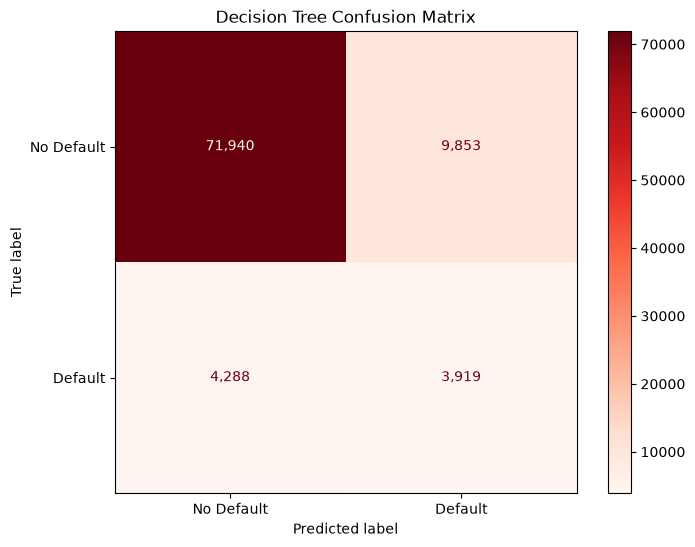

In [297]:
# plots a better visual of confusion matrix
conf_matr = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=conf_matr,
    display_labels=["No Default", "Default"]
)

fig, ax = plt.subplots(figsize=(8,6))
display.plot(
    cmap="Reds",
    values_format=",",
    ax=ax
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

This confusion matrix shows that the model has a tendency to predict a lot of false negatives-- cases where someone did not actually default, but we predicted that they did.

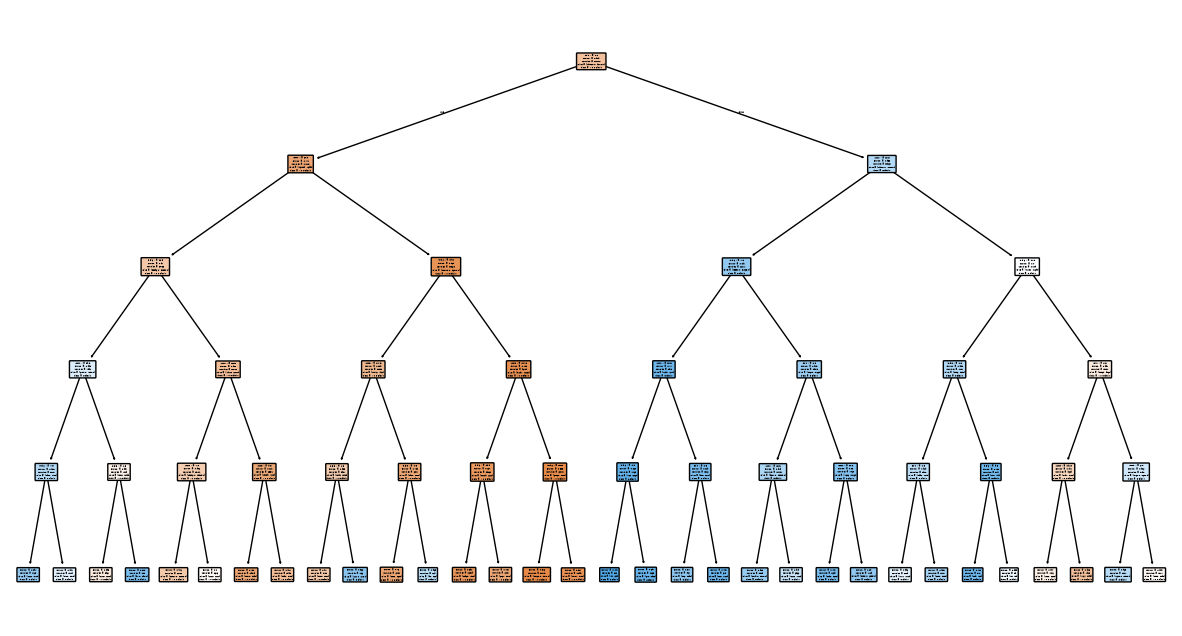

In [298]:
plt.figure(figsize=(15, 8))

plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["No Default", "Default"],
    filled=True,
    rounded=True
)

plt.show()

The above is what the actual decision tree looks like.

In [299]:
# gives the relative importance for each predictor variable
# uses Gini importance
importance = pd.DataFrame({
    "Variable": X.columns,
    "Importance": tree.feature_importances_
})

print(
    importance.sort_values(
        "Importance",
        ascending=False
    )
)

  Variable  Importance
3     Col1    0.553832
0    Acct1    0.270290
5     Del6    0.122903
2    Acct5    0.035023
1    Acct3    0.009156
4     Del3    0.008796


Col1, Acct1, and Del6 are the most influential variables in the split, so they have the most predictive power.

Potential improvement section:

The below code box attempts to use a random forest classifier to improve model accuracy. It is significantly worse at predicting cases where a person does default, so random forest is not a good ensemble method to use. Our baseline method is the best one to use.

In [300]:
# improve f1_score for default cases. try random forest?
from sklearn.ensemble import RandomForestClassifier
tree = RandomForestClassifier(
    max_depth=10,
    max_samples=0.2,
    n_estimators=100,
)

tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)
print(classification_report(y_test, y_pred))

# well that actually made things worse.

              precision    recall  f1-score   support

           0       0.91      1.00      0.95     81793
           1       0.56      0.02      0.04      8207

    accuracy                           0.91     90000
   macro avg       0.73      0.51      0.50     90000
weighted avg       0.88      0.91      0.87     90000

